# 03. SVM

## Préparation

In [1]:
import sys
sys.path.append("..")
import pandas as pd

import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from src.data import X_train, X_test, y_train, y_test
from src.preprocessing import prepro
from src.evaluation import cv

SVM

In [2]:
from sklearn.svm import SVC

pip_svm = Pipeline([
    ("prétraitement", prepro),
    ("model", SVC(class_weight="balanced")),
])

grid_svm = [{"model__kernel": ["linear"], "model__C": [0.01, 0.1, 1, 10]}, {"model__kernel": ["rbf"],    "model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1]},]

clf_svm = GridSearchCV(pip_svm, grid_svm, cv=cv, scoring="f1_macro", n_jobs=-1)
resultats_svm = cross_validate(clf_svm, X_train, y_train, cv=cv, scoring=["f1_macro", "recall", "precision", "accuracy", "roc_auc"],return_estimator=True, n_jobs=-1,)

for i, e in enumerate(resultats_svm["estimator"], 1):
    print(f"tour {i} : {e.best_params_}")

tour 1 : {'model__C': 1, 'model__kernel': 'linear'}
tour 2 : {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
tour 3 : {'model__C': 100, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
tour 4 : {'model__C': 100, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
tour 5 : {'model__C': 10, 'model__kernel': 'linear'}


In [3]:
resultats_svm

{'fit_time': array([0.7045567 , 0.700068  , 0.67822886, 0.69244909, 0.70432091]),
 'score_time': array([0.00775719, 0.00763106, 0.00703692, 0.00781989, 0.00823712]),
 'estimator': [GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
               estimator=Pipeline(steps=[('prétraitement',
                                          ColumnTransformer(transformers=[('ages',
                                                                           Pipeline(steps=[('imp',
                                                                                            SimpleImputer(strategy='median')),
                                                                                           ('sc',
                                                                                            StandardScaler())]),
                                                                           ['Age '
                                                                            'of '

In [4]:
resultats_svm[("test_f1_macro")]

array([0.49913043, 0.45221445, 0.41601473, 0.40181818, 0.48351648])

In [5]:
resultats_svm[("test_roc_auc")]

array([0.47027972, 0.48363636, 0.44363636, 0.43589744, 0.44505495])

In [6]:
for i, e in enumerate(resultats_svm["estimator"], 1):
    print(f"tour {i} : interne {e.best_score_:.3f}  →  externe {resultats_svm['test_f1_macro'][i-1]:.3f}")

tour 1 : interne 0.474  →  externe 0.499
tour 2 : interne 0.465  →  externe 0.452
tour 3 : interne 0.543  →  externe 0.416
tour 4 : interne 0.480  →  externe 0.402
tour 5 : interne 0.562  →  externe 0.484


0.4949494949494949


<Axes: >

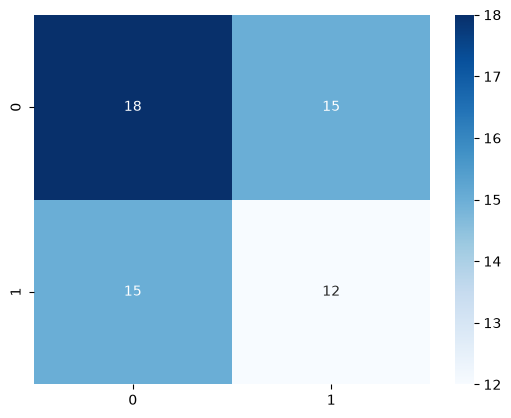

In [7]:
svm_libre = Pipeline([
    ("prétraitement", prepro),
    ("model", SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")),
])
svm_libre.fit(X_train, y_train)

y_pred = svm_libre.predict(X_test)
score = f1_score(y_test, y_pred, average="macro")
print(score)
confusion_matrix_svm = confusion_matrix(y_test, y_pred)

sns.heatmap(confusion_matrix_svm, annot=True, cmap="Blues", fmt="g", annot_kws={"size": 10})

In [8]:
pd.DataFrame(resultats_svm).drop(columns="estimator").to_csv("../results/svm.csv", index=False)